# 02 – Resume classification: baseline

TF-IDF + logistic regression on the 43 categories. This is the first baseline required for the checkpoint; sentence embeddings are compared later.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

In [2]:
resumes = load_dataset("ahmedheakl/resume-atlas")["train"].to_pandas()
resumes = resumes.drop_duplicates("Text").reset_index(drop=True)   # duplicates would leak between train and test

X_train, X_test, y_train, y_test = train_test_split(
    resumes["Text"], resumes["Category"], test_size=0.2, stratify=resumes["Category"], random_state=42)
print(len(X_train), "train /", len(X_test), "test")

9668 train / 2417 test


In [3]:
baseline = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=100_000, sublinear_tf=True),
    LogisticRegression(max_iter=2000, C=10),
)
baseline.fit(X_train, y_train)
pred = baseline.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, pred):.3f}")
print(f"Macro F1: {f1_score(y_test, pred, average='macro'):.3f}")

Accuracy: 0.806
Macro F1: 0.806


In [4]:
report = pd.DataFrame(classification_report(y_test, pred, output_dict=True)).T
report.iloc[:-3].sort_values("f1-score").head(10)   # the 10 hardest categories

,precision,recall,f1-score,support
Management,0.402985,0.421875,0.412214,64.0
BPO,0.677419,0.538462,0.600000,39.0
Designing,0.632653,0.632653,0.632653,49.0
Consultant,0.728814,0.623188,0.671875,69.0
React Developer,0.812500,0.590909,0.684211,22.0
Sales,0.602151,0.823529,0.695652,68.0
Web Designing,0.775510,0.678571,0.723810,56.0
Automobile,0.750000,0.700000,0.724138,60.0
Arts,0.809524,0.680000,0.739130,50.0
Finance,0.761905,0.727273,0.744186,66.0


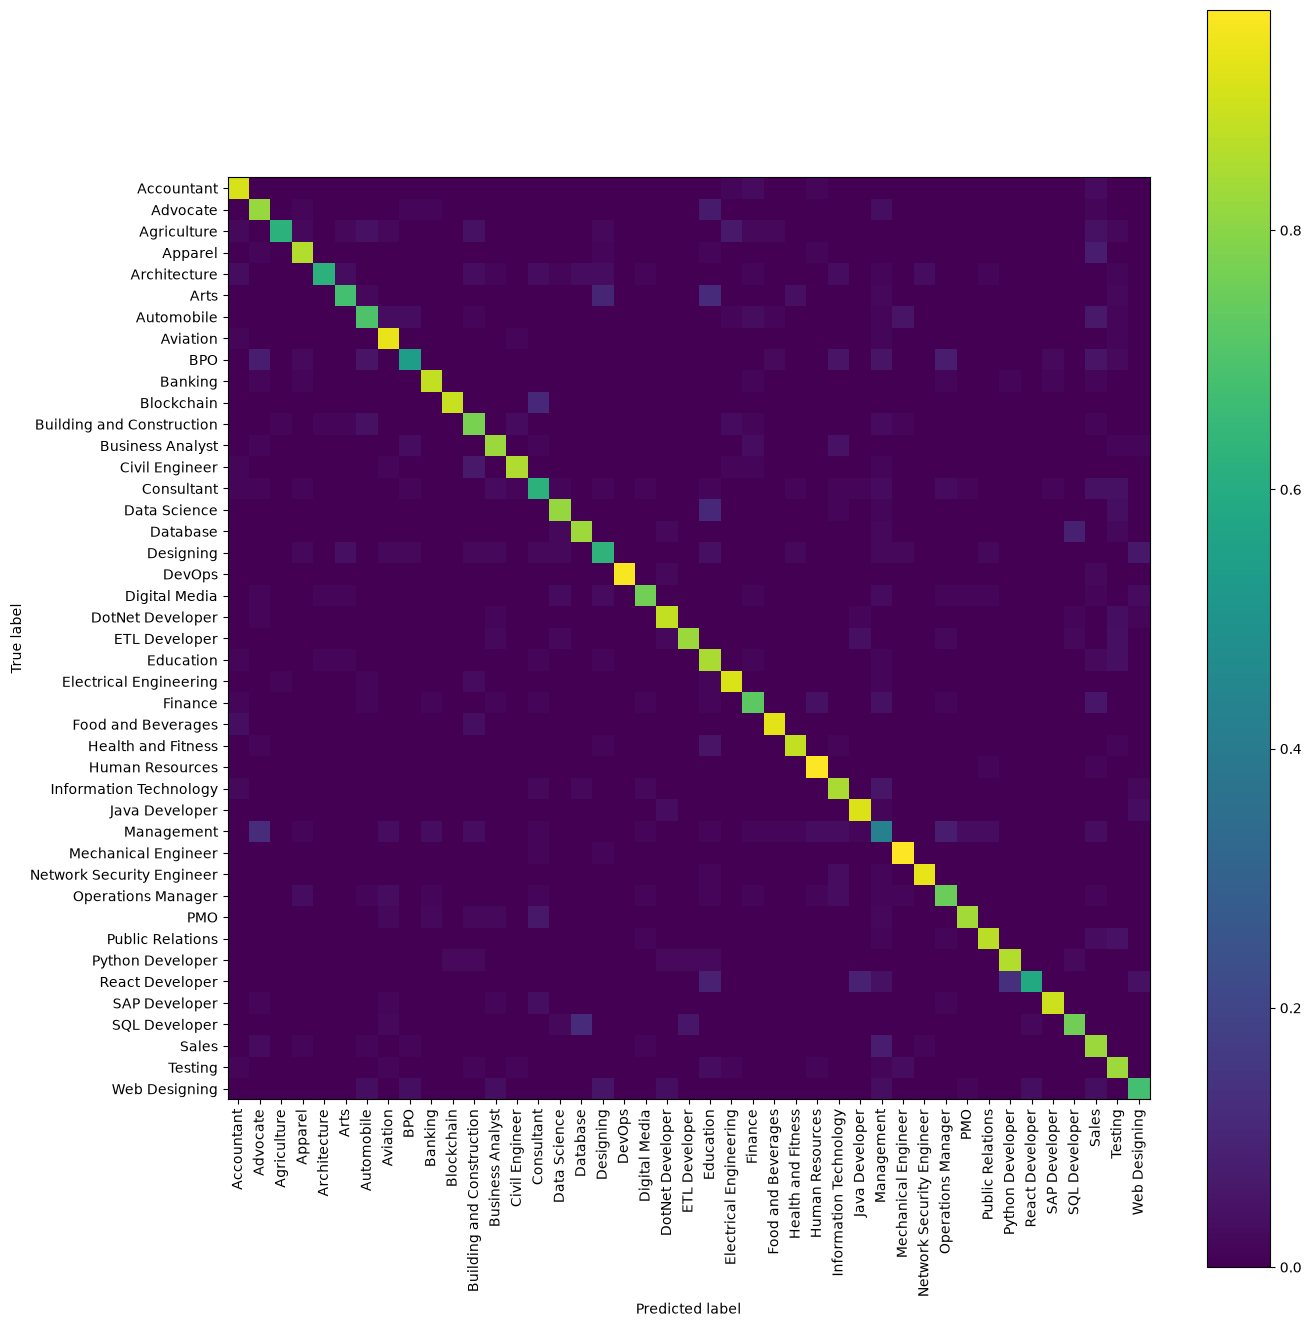

In [5]:
fig, ax = plt.subplots(figsize=(14, 14))
ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, xticks_rotation=90, include_values=False, normalize="true")
plt.tight_layout(); plt.show()

In [6]:
# Most frequent confusions
errors = pd.DataFrame({"true": y_test, "pred": pred})
errors = errors[errors["true"] != errors["pred"]]
errors.value_counts().head(10)

true           pred              
Management     Advocate              8
Arts           Education             6
SQL Developer  Database              6
Data Science   Education             6
Sales          Management            5
Management     Operations Manager    5
Apparel        Sales                 5
Arts           Designing             5
Database       SQL Developer         4
Automobile     Sales                 4
Name: count, dtype: int64

In [7]:
# Most predictive words for a few categories
vec, clf = baseline.named_steps["tfidfvectorizer"], baseline.named_steps["logisticregression"]
words = np.array(vec.get_feature_names_out())
for cat in ["Data Science", "Java Developer", "Human Resources"]:
    i = list(clf.classes_).index(cat)
    print(cat, "->", ", ".join(words[np.argsort(clf.coef_[i])[::-1][:12]]))

Data Science -> science, data science, scientist, data scientist, learning, science teacher, data, machine learning, machine, students, models, research
Java Developer -> java, java developer, developer, spring, hibernate, senior java, code, application, web, software, jsp, j2ee
Human Resources -> hr, human resources, human, resources, employee, recruitment, employees, payroll, benefits, compensation, employee relations, talent


## Findings

- **Baseline score:** accuracy **0.806** and macro F1 **0.806** on 2,417 test resumes (43 classes, random guess = 0.023).
- **Hardest categories:** Management (F1 0.41), BPO (0.60), Designing (0.63), Consultant (0.67): broad job families whose resumes share vocabulary with other categories.
- **Most frequent confusions:** Management → Advocate, Management → Operations Manager, SQL Developer ↔ Database, Arts → Designing / Education. Most of them are close jobs in reality: some resumes would fit both labels.
- **Predictive words are sensible:** Java Developer → java, spring, hibernate, j2ee; Human Resources → hr, recruitment, payroll, benefits. The model relies on job-specific keywords, which makes it easy to explain.